In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


✅ All imports done (no NLTK, no imblearn, no lightgbm — pure sklearn)
✅ Train: (197999, 15) | Test: (102000, 14)
⏳ Cleaning text (minimal, no stemming)...
✅ Done in 16.8s
  ORIG:  She might be a bright spot for a party keou on Oahu dominated by greedy criminal
  CLEAN: she might be a bright spot for a party keou on oahu dominated by greedy criminal

  ORIG:  Under Alaska law, a non-tribal member is not bound to tribal court.. Living in a
  CLEAN: under alaska law a non tribal member is not bound to tribal court living in a pa

  ORIG:  in the future please spare me your strawman drivel, and if you can't manage an i
  CLEAN: in the future please spare me your strawman drivel and if you can't manage an in

✅ Features: Train (197999, 27) | Test (102000, 26)
⏳ Word TF-IDF (35K, trigrams, no stop_words)...
✅ Word: 35000 features in 93.7s
⏳ Char TF-IDF (25K)...
✅ Char: 25000 features in 120.7s
✅ Total features: 60019
✅ Train: 158,399 | Val: 39,600
⏳ LinearSVC...

  LinearSVC (custom): Acc=0.

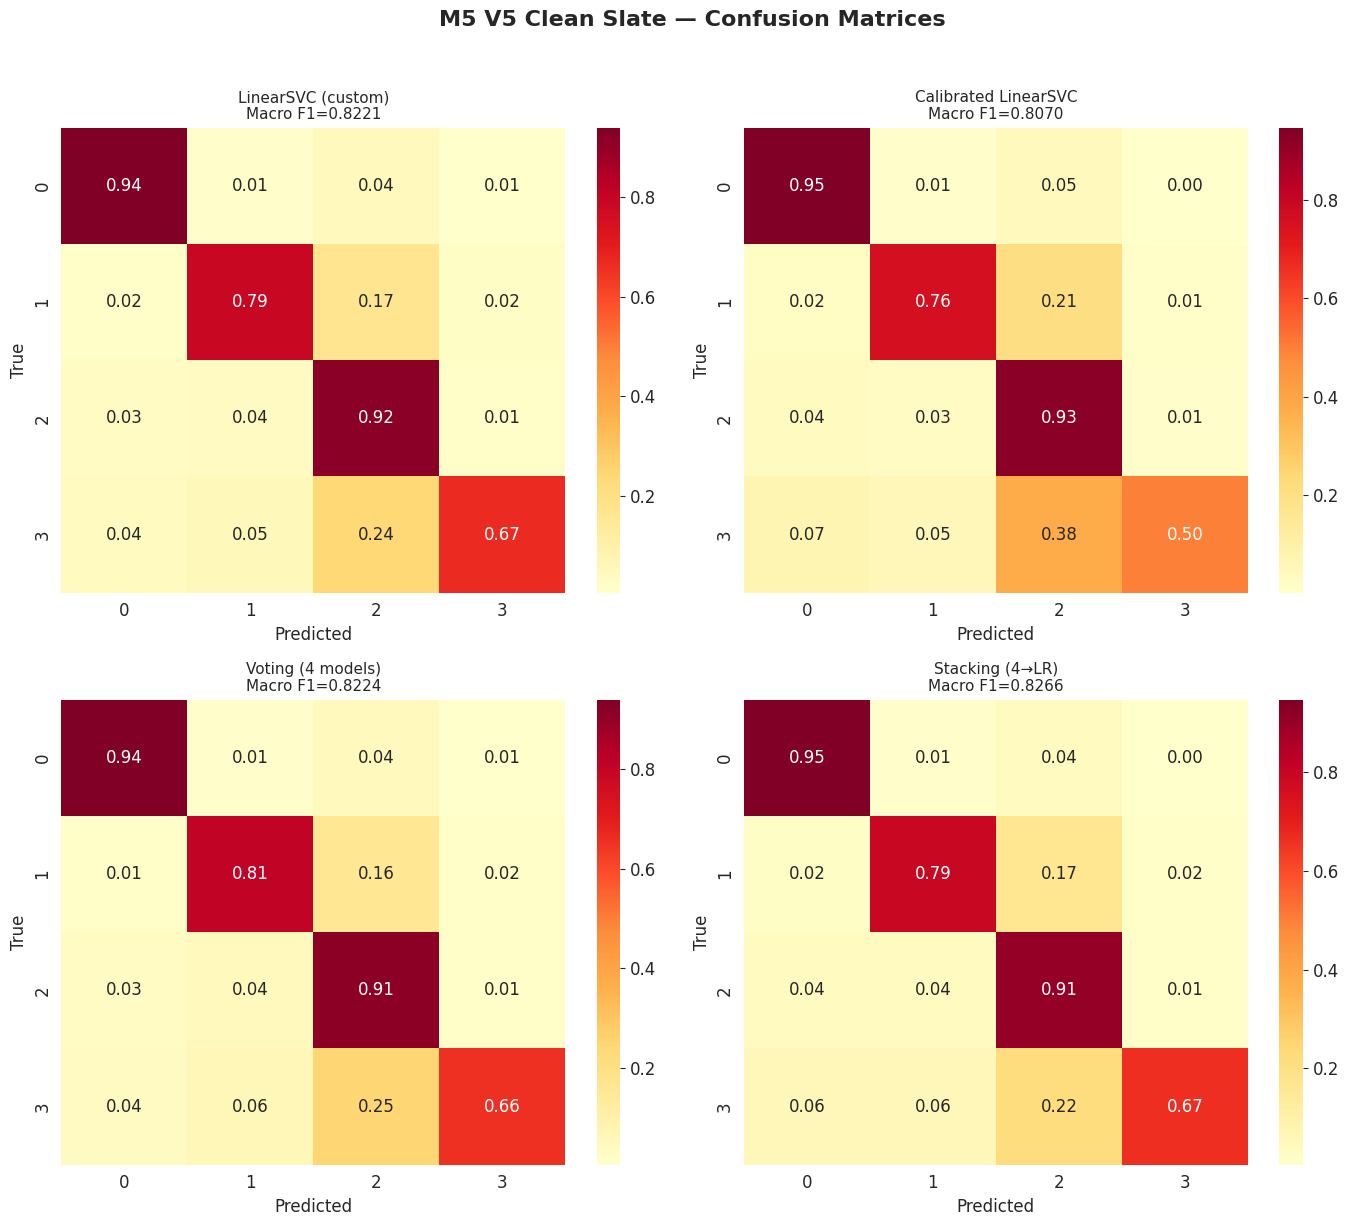


🏆 Retraining top 3 on ALL data...
⏳ LinearSVC...
⏳ Stacking...
⏳ Voting...
✅ All retrained!

📋 Submissions...
  ✅ submission_linearsvc.csv | {np.int64(0): np.int64(56739), np.int64(1): np.int64(8195), np.int64(2): np.int64(34166), np.int64(3): np.int64(2900)}
  ✅ submission_voting_ensemble.csv | {np.int64(0): np.int64(56615), np.int64(1): np.int64(8566), np.int64(2): np.int64(33968), np.int64(3): np.int64(2851)}
  ✅ submission_stacking_ensemble.csv | {np.int64(0): np.int64(57474), np.int64(1): np.int64(8131), np.int64(2): np.int64(33655), np.int64(3): np.int64(2740)}

🏆 Main = Stacking | {np.int64(0): np.int64(57474), np.int64(1): np.int64(8131), np.int64(2): np.int64(33655), np.int64(3): np.int64(2740)}


In [2]:
# %% [markdown]
# # 🏆 Milestone 5 V5: Clean Slate — Only What Works
#
# **Lesson from V1-V4: Strip everything that doesn't help.**
#
# | Run | Kaggle | What helped | What hurt |
# | --- | --- | --- | --- |
# | V1 | 0.826 | lemma, trigrams, 45K, balanced | — |
# | V2 | 0.823 | no stopwords, 60K | custom weights for ensembles |
# | V3 | 0.826 | hybrid weights, 60K, no stopwords | — |
# | V4 | OOM | — | ROS, SMOTE, LightGBM, pseudo-labels, regex stemming |
#
# **V5 Design: MINIMAL. Only proven winners.**
# - ✅ NO stemming/lemmatization (regex stemming hurt, NLTK is illegal)
# - ✅ NO stop_words removal (V2 proved this helps)
# - ✅ 60K features (35K word + 25K char)
# - ✅ balanced for ensembles, custom for LinearSVC (V3 hybrid)
# - ✅ No ROS/SMOTE (class_weight handles imbalance better)
# - ✅ No LightGBM (0.757 = too weak, adds noise to blending)
# - ✅ No pseudo-labeling (only added Labels 0/2, made imbalance worse)
# - ✅ Only allowed libraries (no NLTK, no PyTorch)

# %%
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
from scipy.sparse import hstack, csr_matrix

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

print("✅ All imports done (no NLTK, no imblearn, no lightgbm — pure sklearn)")

# %% [markdown]
# NOTE: M5 Questions (Q1-Q10) already answered in milestone_5_final_push.py

# %%
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])
print(f"✅ Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## 1. Text Cleaning (Minimal — No Stemming)
#
# V4 proved regex stemming HURT scores ("Under"→"und", "tribal"→"trib").
# NLTK lemmatizer is NOT allowed per competition rules.
# Solution: Just clean noise (URLs, HTML, numbers) and lowercase. Let TF-IDF do the rest.

# %%
def clean_text(text):
    """Minimal text cleaning — NO stemming, NO lemmatization."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\b\d+\b', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("⏳ Cleaning text (minimal, no stemming)...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Done in {time.time()-t0:.1f}s")

for i in range(3):
    print(f"  ORIG:  {str(train['comment'].iloc[i])[:80]}")
    print(f"  CLEAN: {train['comment_clean'].iloc[i][:80]}\n")

# %% [markdown]
# ## 2. Feature Engineering

# %%
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Features: Train {train.shape} | Test {test.shape}")

# %% [markdown]
# ## 3. TF-IDF (35K word + 25K char = 60K)

# %%
print("⏳ Word TF-IDF (35K, trigrams, no stop_words)...")
t0 = time.time()
tfidf_word = TfidfVectorizer(
    max_features=35000, ngram_range=(1, 3),
    min_df=3, max_df=0.9, sublinear_tf=True
)
X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word: {X_word_train.shape[1]} features in {time.time()-t0:.1f}s")

print("⏳ Char TF-IDF (25K)...")
t0 = time.time()
tfidf_char = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5),
    max_features=25000, min_df=3, max_df=0.9, sublinear_tf=True
)
X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char: {X_char_train.shape[1]} features in {time.time()-t0:.1f}s")

# %% [markdown]
# ## 4. Combine Features

# %%
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = ["emoticon_1", "emoticon_2", "emoticon_3", "disability", "has_detection"]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)
y_all = train["label"].values

skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
for col in skewed_cols:
    idx = numeric_features.index(col)
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)

X_all = hstack([X_word_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Total features: {X_all.shape[1]}")

# %% [markdown]
# ## 5. Train-Val Split

# %%
indices = np.arange(len(y_all))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y_all, random_state=42)
X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]
print(f"✅ Train: {len(y_tr):,} | Val: {len(y_vl):,}")

# %% [markdown]
# ## 6. Models

# %%
results = []
def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})
    print(f"\n  {name}: Acc={acc:.4f} | Macro F1={f1_m:.4f} | Weighted F1={f1_w:.4f}")
    print(classification_report(y_true, y_pred))
    return f1_m

CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}

# %%
# Model 1: LinearSVC (custom weights — best individual)
print("⏳ LinearSVC...")
t0 = time.time()
lsvc = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr, y_tr)
evaluate_model("LinearSVC (custom)", y_vl, lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 2: Calibrated LinearSVC (balanced — for ensembles)
print("⏳ Calibrated LinearSVC...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LinearSVC", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 3: LR (balanced)
print("⏳ LR...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 4: SGD (balanced)
print("⏳ SGD...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD (balanced)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 5: PAC (balanced)
print("⏳ PAC...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    C=0.1, class_weight="balanced",
    max_iter=3000, n_jobs=-1, random_state=42
)
pac.fit(X_tr, y_tr)
evaluate_model("PAC (balanced)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 7. Ensembles (balanced — proven best on Kaggle)

# %%
print("⏳ Voting Ensemble...")
t0 = time.time()
voting_clf = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_clf.fit(X_tr, y_tr)
evaluate_model("Voting (4 models)", y_vl, voting_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
print("⏳ Stacking Ensemble...")
t0 = time.time()
stacking_clf = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_clf.fit(X_tr, y_tr)
evaluate_model("Stacking (4→LR)", y_vl, stacking_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 8. Model Comparison

# %%
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("  M5 V5 CLEAN SLATE — Model Comparison (sorted by Macro F1)")
print("="*80)
print(results_df.to_string(index=False))

# %% [markdown]
# ## 9. Confusion Matrices

# %%
model_pred_map = {
    "LinearSVC (custom)": lsvc.predict(X_vl),
    "Calibrated LinearSVC": cal_lsvc.predict(X_vl),
    "Voting (4 models)": voting_clf.predict(X_vl),
    "Stacking (4→LR)": stacking_clf.predict(X_vl),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, preds) in zip(axes.ravel(), model_pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nMacro F1={f1:.4f}", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

plt.suptitle("M5 V5 Clean Slate — Confusion Matrices", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 10. Retrain & Submit (only top 3)

# %%
print("\n🏆 Retraining top 3 on ALL data...")

# LinearSVC (custom)
print("⏳ LinearSVC...")
lsvc_final = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y_all)

# Stacking (balanced)
print("⏳ Stacking...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_all, y_all)

# Voting (balanced)
print("⏳ Voting...")
voting_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_final.fit(X_all, y_all)

print("✅ All retrained!")

# %%
print("\n📋 Submissions...")
for name, model in [("linearsvc", lsvc_final), ("voting_ensemble", voting_final),
                     ("stacking_ensemble", stacking_final)]:
    preds = model.predict(X_test_all)
    sub = sample.copy(); sub["label"] = preds
    sub.to_csv(f"submission_{name}.csv", index=False)
    print(f"  ✅ submission_{name}.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

submission = sample.copy()
submission["label"] = stacking_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"\n🏆 Main = Stacking | {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")

# %% [markdown]
# ## Summary
# V5 = V3 without NLTK lemmatization. Pure minimal approach.
# If this matches V3 (0.826), it proves lemmatization wasn't helping.
# If it beats V3, even better — simpler is better.
